# 🟢 ark-beta-mini-v3 — Image-to-Text (Sequence Generation)

## 🔴 Imports

In [17]:
from pathlib import Path
from datetime import datetime
import random, json, time, math, os, sys
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import re
from collections import Counter
import torch.nn.functional as F
import psutil
from collections import defaultdict
import textwrap

## ⚙️ Configuration

In [18]:
ROOT = Path.cwd()
if not (ROOT / "dataset").exists() and (ROOT / "ark-vision" / "dataset").exists():
    ROOT = ROOT / "ark-vision"

DATA = ROOT / "dataset" / "Alphabet_VISION_Dataset"
TOKENIZER_PATH = ROOT / "tokenizer" / "bpe-tokenizer_alphabet_nlp_dataset_29,000.json"
MODEL_NAME = "ark-beta-mini-v3"
MODEL_LOGS = ROOT / "logs" / MODEL_NAME
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

SELECTED_DATASETS = ["various_images"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_MODE = "L" if DEVICE.type == "cpu" else "RGB"
IMAGE_CHANNELS = 1 if IMAGE_MODE == "L" else 3

BATCH_SIZE = 2
EPOCHS_PER_RUN = 20
LR = 1e-3
WEIGHT_DECAY = 0.0
NUM_WORKERS = 0
MAX_SEQUENCE_LENGTH = 64
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
MAX_GRAD_NORM = 1.0

if DEVICE.type == "cpu":
    torch.set_num_threads(2)

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("Project root:", ROOT)
print("Dataset root:", DATA)
print("Tokenizer:", TOKENIZER_PATH, "| exists:", TOKENIZER_PATH.is_file())
print("Selected datasets:", SELECTED_DATASETS)
print(f"Image mode: {IMAGE_MODE} ({IMAGE_CHANNELS} channel(s)); original image dimensions preserved")
print("Device:", DEVICE)

Project root: F:\pyvenv\ARK\ark-vision
Dataset root: F:\pyvenv\ARK\ark-vision\dataset\Alphabet_VISION_Dataset
Tokenizer: F:\pyvenv\ARK\ark-vision\tokenizer\bpe-tokenizer_alphabet_nlp_dataset_29,000.json | exists: True
Selected datasets: ['various_images']
Image mode: L (1 channel(s)); original image dimensions preserved
Device: cpu


## 🗣️ BPE Tokenizer

In [19]:
try:
    from tokenizers import Tokenizer
except ImportError as exc:
    raise ImportError("کتابخانهٔ tokenizers نصب نیست. در صورت نیاز اجرا کنید: %pip install tokenizers") from exc

if not TOKENIZER_PATH.is_file():
    raise FileNotFoundError(f"Tokenizer JSON not found: {TOKENIZER_PATH}")

tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
# Add dedicated sequence markers for training. Existing vocabulary IDs remain unchanged.
tokenizer.add_special_tokens(["[PAD]", "[BOS]", "[EOS]"])
PAD_ID = tokenizer.token_to_id("[PAD]")
BOS_ID = tokenizer.token_to_id("[BOS]")
EOS_ID = tokenizer.token_to_id("[EOS]")
VOCAB_SIZE = tokenizer.get_vocab_size()

print(f"Tokenizer loaded: {TOKENIZER_PATH.name}")
print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"Special IDs: PAD={PAD_ID}, BOS={BOS_ID}, EOS={EOS_ID}")

def tokenizer_smoke_test(text):
    encoded = tokenizer.encode(text)
    decoded = tokenizer.decode(encoded.ids, skip_special_tokens=True)
    print("Input:   ", repr(text))
    print("Token IDs:", encoded.ids[:40], ("..." if len(encoded.ids) > 40 else ""))
    print("Tokens:  ", encoded.tokens[:40], ("..." if len(encoded.tokens) > 40 else ""))
    print("Decoded: ", repr(decoded))
    print("Exact round-trip:", decoded == text)
    return encoded

# Check both scripts and a short English sample.
_ = tokenizer_smoke_test("سلام دنیا")
_ = tokenizer_smoke_test("می‌خواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.")
_ = tokenizer_smoke_test("مدل CNN برای Image-to-Text طراحی شده است.")
_ = tokenizer_smoke_test("Hello world")

Tokenizer loaded: bpe-tokenizer_alphabet_nlp_dataset_29,000.json
Vocabulary size: 29,876
Special IDs: PAD=29873, BOS=29874, EOS=29875
Input:    'سلام دنیا'
Token IDs: [5111, 2638] 
Tokens:   ['Ø³ÙĦØ§Ùħ', 'ĠØ¯ÙĨÛĮØ§'] 
Decoded:  'سلام دنیا'
Exact round-trip: True
Input:    'می\u200cخواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.'
Token IDs: [331, 1477, 152, 10870, 494, 1127, 213, 903, 237, 793, 10370, 317, 992, 132, 160, 1982, 15] 
Tokens:   ['ÙħÛĮ', 'âĢ', 'Į', 'Ø®ÙĪØ§ÙĩÙħ', 'ĠÙħØ¯ÙĦ', 'ĠØªØµÙĪÛĮØ±', 'ĠØ¨Ùĩ', 'ĠÙħØªÙĨ', 'ĠØ±Ø§', 'ĠØ¢ÙħÙĪØ²Ø´', 'ĠØ¯ÙĩÙħ', 'ØĽ', 'ĠÙĨØ³Ø®Ùĩ', 'Ù', 'Ķ', 'ĠÛ³', '.'] 
Decoded:  'می\u200cخواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.'
Exact round-trip: True
Input:    'مدل CNN برای Image-to-Text طراحی شده است.'
Token IDs: [2321, 5171, 276, 7337, 14, 4246, 14, 5497, 856, 336, 220, 15] 
Tokens:   ['ÙħØ¯ÙĦ', 'ĠCNN', 'ĠØ¨Ø±Ø§ÛĮ', 'ĠImage', '-', 'to', '-', 'Text', 'ĠØ·Ø±Ø§ØŃÛĮ', 'ĠØ´Ø¯Ùĩ', 'ĠØ§Ø³Øª', '.'] 
Decoded:  'مدل CNN برای Image-to-Text طراحی شده است.'
Exact rou

In [20]:
def test_sequence_tokens(text):
    encoded = tokenizer.encode(text)

    # Simulate the sequence used for training.
    sequence = [BOS_ID] + encoded.ids + [EOS_ID]

    print("Text:", repr(text))
    print("BOS at start:", sequence[0] == BOS_ID)
    print("EOS at end:", sequence[-1] == EOS_ID)
    print("EOS count:", sequence.count(EOS_ID))
    print("Sequence length:", len(sequence))
    print("Decoded:", repr(
        tokenizer.decode(sequence, skip_special_tokens=True)
    ))

    assert sequence[0] == BOS_ID
    assert sequence[-1] == EOS_ID
    assert sequence.count(EOS_ID) == 1

    return sequence

test_sequence_tokens("A man in a green outfit and a metal mask")
test_sequence_tokens("AI-generated character")

Text: 'A man in a green outfit and a metal mask'
BOS at start: True
EOS at end: True
EOS count: 1
Sequence length: 18
Decoded: 'A man in a green outfit and a metal mask'
Text: 'AI-generated character'
BOS at start: True
EOS at end: True
EOS count: 1
Sequence length: 9
Decoded: 'AI-generated character'


[29874, 3976, 14, 17528, 3162, 458, 799, 973, 29875]

## 🗂️ Dataset — Image/Text Pairs

In [21]:
IMAGE_SIZE = 128

def prepare_image(image):
    """Convert image to the selected mode and resize to a fixed size."""
    image = ImageOps.exif_transpose(image).convert(IMAGE_MODE)

    image = ImageOps.fit(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR,
    )

    arr = np.asarray(image, dtype=np.float32).copy() / 255.0

    if IMAGE_MODE == "L":
        # (H, W) -> (1, H, W)
        arr = arr[None, :, :]
    else:
        # (H, W, C) -> (C, H, W)
        arr = arr.transpose(2, 0, 1)

    return torch.from_numpy(arr).contiguous()

def encode_caption(text):
    ids = tokenizer.encode(text).ids[:MAX_SEQUENCE_LENGTH-2]
    return [BOS_ID] + ids + [EOS_ID]

def report_duplicate_captions(items, split_name="train"):
    """
    Report exact duplicate captions within each dataset folder.
    Duplicate key: (folder, identity, caption).
    """
    groups = defaultdict(list)

    for item in items:
        path, identity, kind, ids, caption = item

        # Check duplicates separately within each dataset folder.
        key = (
            path.parent,
            identity.strip(),
            caption.strip(),
        )
        groups[key].append(path)

    duplicates = {
        key: paths
        for key, paths in groups.items()
        if len(paths) > 1
    }

    print(f"\n========== DUPLICATE CAPTIONS: {split_name.upper()} ==========")

    if not duplicates:
        print("No exact duplicate captions found within dataset folders.")
        print("====================================================\n")
        return duplicates

    duplicate_count = sum(len(paths) - 1 for paths in duplicates.values())

    print(f"Duplicate caption groups: {len(duplicates)}")
    print(f"Extra duplicate samples: {duplicate_count}")

    for (folder, identity, caption), paths in sorted(
        duplicates.items(),
        key=lambda x: (str(x[0][0]), x[0][1], x[0][2])
    ):
        print(f"\nFolder: {folder}")
        print(f"Identity: {identity or '-'}")
        print(f"Caption: {caption}")
        print(f"Occurrences: {len(paths)}")

        for path in paths:
            print(f"  - {path.name}")

    print("\n====================================================\n")
    return duplicates

class ImageTextDataset(Dataset):
    def __init__(self, split):
        self.items, self.skipped = [], []
        split_root = DATA / split
        if not split_root.is_dir():
            raise FileNotFoundError(f"Split directory not found: {split_root}")
        for dataset_name in SELECTED_DATASETS:
            folder = split_root / dataset_name
            if not folder.is_dir():
                raise FileNotFoundError(f"Selected dataset folder not found: {folder}")
            for path in sorted(folder.rglob("*")):
                if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                label_path = path.with_suffix(".txt")
                if not label_path.is_file():
                    self.skipped.append((str(path), "missing .txt"))
                    continue
                
                label_content = label_path.read_text(encoding="utf-8-sig").strip()
            
                if not label_content:
                    self.skipped.append((str(path), "empty label"))
                    continue
                
                
                # Supports both:
                # Identity | description
                # Image description
                
                identity = ""
                
                if "|" in label_content:
                    parts = label_content.split("|", maxsplit=1)
                    identity = parts[0].strip()
                    text = parts[1].strip()
                
                    if not identity:
                        self.skipped.append((str(path), "empty character name"))
                        continue
                
                    if not text:
                        self.skipped.append((str(path), "empty caption"))
                        continue
                else:
                    text = label_content
                
                if not text:
                    self.skipped.append((str(path), "empty caption"))
                    continue
                
                # Train the model to generate both identity and description.
                if identity:
                    target_text = f"{identity} | {text}"
                else:
                    target_text = text
                
                ids = encode_caption(target_text)
                
                if len(ids) < 2:
                    self.skipped.append((str(path), "empty token sequence"))
                    continue
                
                self.items.append(
                    (path, identity, "text", ids, target_text)
                )


        if not self.items:
            raise ValueError(f"No image/text pairs found for split={split}")
            
        self.text_count = len(self.items)
        print(
            f"{split}: {len(self.items):,} image-caption pairs "
            f"| skipped={len(self.skipped):,}"
        )
        if self.skipped[:3]:
            print("Skipped examples:", self.skipped[:3])

    def __len__(self):
        return len(self.items)

    
    def __getitem__(self, idx):
        path, identity, kind, target, text = self.items[idx]
    
        try:
            with Image.open(path) as im:
                image = prepare_image(im)
        except (UnidentifiedImageError, OSError) as exc:
            raise RuntimeError(
                f"Could not read image {path}: {exc}"
            ) from exc
    
        if kind == "class":
            return image, 0, target, [], text, str(path)
    
        return image, 1, -1, target, text, str(path)


def collate_batch(batch):
    images, kinds, class_targets, seq_targets, texts, paths = zip(*batch)
    # Pad only to the largest H/W in this batch; never resize the source images.
    channels = images[0].shape[0]
    max_h = max(img.shape[1] for img in images)
    max_w = max(img.shape[2] for img in images)
    padded_images = torch.zeros((len(images), channels, max_h, max_w), dtype=images[0].dtype)
    for i, img in enumerate(images):
        _, h, w = img.shape
        padded_images[i, :, :h, :w] = img
    images = padded_images
    kinds = torch.tensor(kinds, dtype=torch.long)
    class_targets = torch.tensor(class_targets, dtype=torch.long)
    max_len = max((len(s) for s in seq_targets), default=0)
    seq_tensor = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    for i, seq in enumerate(seq_targets):
        if seq:
            seq_tensor[i, :len(seq)] = torch.tensor(seq, dtype=torch.long)
    return images, kinds, class_targets, seq_tensor, list(texts), list(paths)


def get_ram_mb():
    """Current Python process RAM usage in MB."""
    return psutil.Process(os.getpid()).memory_info().rss / (1024 ** 2)


def load_and_report_datasets(samples_per_folder=1, seed=None):
    rng = random.Random(seed)
    datasets = {}
    total_samples = 0
    total_skipped = 0

    print("\n========== DATASET REPORT ==========")
    ram_start = get_ram_mb()
    print(f"RAM before loading: {ram_start:.1f} MB")

    for split in ("train", "valid", "test"):
        ram_before = get_ram_mb()
        ds = ImageTextDataset(split)
        ram_after = get_ram_mb()
        datasets[split] = ds

        # Check exact duplicate captions in TRAIN only.
        if split == "train":
            report_duplicate_captions(ds.items, split_name="train")
    
        total_samples += len(ds)
        total_skipped += len(ds.skipped)

        # Group examples by image parent folder.
        folders = {}
        for item in ds.items:
            folders.setdefault(item[0].parent, []).append(item)

        print(
            f"\n[{split.upper()}] "
            f"samples={len(ds)} | skipped={len(ds.skipped)} "
            f"| folders={len(folders)} "
            f"| RAM={ram_after:.1f} MB "
            f"(delta={ram_after - ram_before:+.1f} MB)"
        )

        for folder, items in sorted(folders.items(), key=lambda x: str(x[0])):
            examples = rng.sample(items, min(samples_per_folder, len(items)))

            print(f"  {folder.name}/: {len(items)} samples")

            for path, character, kind, ids, caption in examples:
                # Remove duplicated identity from display only.
                display_caption = caption.strip()
            
                if character and "|" in display_caption:
                    prefix, description = display_caption.split("|", maxsplit=1)
            
                    if prefix.strip() == character.strip():
                        display_caption = description.strip()
            
                print(
                    f"    {path.name} | "
                    f"{character or '-'} | "
                    f"{display_caption}"
                )

    ram_end = get_ram_mb()

    print("\n========== SUMMARY ==========")
    print(
        f"Total samples: {total_samples} "
        f"(train={len(datasets['train'])}, "
        f"valid={len(datasets['valid'])}, "
        f"test={len(datasets['test'])})"
    )
    print(f"Total skipped: {total_skipped}")
    print(f"RAM at end: {ram_end:.1f} MB")
    print(f"RAM increase: {ram_end - ram_start:+.1f} MB")
    print("=============================\n")

    return datasets


loaded_datasets = load_and_report_datasets(
    samples_per_folder=1,
    seed=None,
)

train_dataset = loaded_datasets["train"]
valid_dataset = loaded_datasets["valid"]
test_dataset = loaded_datasets["test"]


# Build the identity gallery from training samples only.
identity_gallery = [
    {
        "name": identity,
        "caption": caption,
        "path": str(path),
    }
    for path, identity, kind, ids, caption in train_dataset.items
    if identity
]

if identity_gallery:
    print(
        f"Identity gallery: {len(identity_gallery)} entries | "
        f"characters={len({x['name'] for x in identity_gallery})}"
    )
else:
    print("WARNING: No identity labels found in training data.")


========== DATASET REPORT ==========
RAM before loading: 541.2 MB
train: 19 image-caption pairs | skipped=0

========== DUPLICATE CAPTIONS: TRAIN ==========
No exact duplicate captions found within dataset folders.


[TRAIN] samples=19 | skipped=0 | folders=1 | RAM=541.2 MB (delta=+0.0 MB)
  various_images/: 19 samples
    cheyava_falls.jpg | Cheyava Falls | An image of Cheyava Falls, where the white markings might be traces of ancient microbial activity
valid: 3 image-caption pairs | skipped=0

[VALID] samples=3 | skipped=0 | folders=1 | RAM=541.2 MB (delta=+0.0 MB)
  various_images/: 3 samples
    egyptian_pyramids.png | Egyptian Pyramids | The three egyptian pyramids in Cairo
test: 8 image-caption pairs | skipped=0

[TEST] samples=8 | skipped=0 | folders=1 | RAM=541.2 MB (delta=+0.0 MB)
  various_images/: 8 samples
    doctor_doom.jpeg | Doctor Doom | Doctor Doom in the film Avengers: Doomsday

========== SUMMARY ==========
Total samples: 30 (train=19, valid=3, test=8)
Total skippe

## 🔄 DataLoaders

In [22]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=collate_batch)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, collate_fn=collate_batch)

batch = next(iter(train_loader))
print("Image batch:", tuple(batch[0].shape))
print("Task kinds (0=class, 1=sequence):", batch[1].tolist())
print("Class targets:", batch[2].tolist())
print("Sequence target shape:", tuple(batch[3].shape))
print("Train/valid/test:", len(train_dataset), len(valid_dataset), len(test_dataset))

Image batch: (2, 1, 128, 128)
Task kinds (0=class, 1=sequence): [1, 1]
Class targets: [-1, -1]
Sequence target shape: (2, 26)
Train/valid/test: 19 3 8


In [23]:
def audit_dataset_eos(dataset, name):
    missing_bos = 0
    missing_eos = 0
    wrong_eos_count = 0
    over_length = 0

    for path, character, kind, ids, text in dataset.items:
        if not ids or ids[0] != BOS_ID:
            missing_bos += 1

        if not ids or ids[-1] != EOS_ID:
            missing_eos += 1

        if ids.count(EOS_ID) != 1:
            wrong_eos_count += 1

        if len(ids) > MAX_SEQUENCE_LENGTH:
            over_length += 1

    print(f"\n[{name}] EOS audit")
    print(f"Samples: {len(dataset)}")
    print(f"Missing BOS: {missing_bos}")
    print(f"Missing EOS: {missing_eos}")
    print(f"EOS count != 1: {wrong_eos_count}")
    print(f"Over max length: {over_length}")


audit_dataset_eos(train_dataset, "TRAIN")
audit_dataset_eos(valid_dataset, "VALID")
audit_dataset_eos(test_dataset, "TEST")


[TRAIN] EOS audit
Samples: 19
Missing BOS: 0
Missing EOS: 0
EOS count != 1: 0
Over max length: 0

[VALID] EOS audit
Samples: 3
Missing BOS: 0
Missing EOS: 0
EOS count != 1: 0
Over max length: 0

[TEST] EOS audit
Samples: 8
Missing BOS: 0
Missing EOS: 0
EOS count != 1: 0
Over max length: 0


## 💾 Checkpointing — Save and Resume

In [24]:
# True: resume from best.pt.
# False: start a new training run.
AUTO_RESUME = True

MODEL_LOGS = Path(MODEL_LOGS)
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# Find runs containing best.pt only.
checkpoint_runs = [
    p for p in MODEL_LOGS.iterdir()
    if p.is_dir() and (p / "best.pt").is_file()
]

if AUTO_RESUME and checkpoint_runs:
    RUN_DIR = max(
        checkpoint_runs,
        key=lambda p: (p / "best.pt").stat().st_mtime
    )
    RESUME_RUN_ID = RUN_DIR.name
    RESUMING = True
else:
    RUN_DIR = MODEL_LOGS / RUN_ID
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    RESUME_RUN_ID = None
    RESUMING = False

BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"

# Use best.pt for testing and resuming.
CHECKPOINT_PATH = BEST_CHECKPOINT_PATH
RESUME_CHECKPOINT_PATH = BEST_CHECKPOINT_PATH

HISTORY_PATH = RUN_DIR / "history.json"
PLOT_PATH = RUN_DIR / "training_plot.png"
TRAINING_LOG_PATH = RUN_DIR / "training.txt"

# ---------------------------------------------------------
# Training state
# ---------------------------------------------------------

accumulated_training_time = 0.0
start_epoch = 1
history = {
    "train_loss": [],
    "valid_loss": [],
}
best_val_loss = float("inf")


def log_training(message):
    """Append a timestamped message to training.txt."""
    timestamp = datetime.now().isoformat(timespec="seconds")
    line = f"[{timestamp}] {message}"
    print(line)

    with open(TRAINING_LOG_PATH, "a", encoding="utf-8") as f:
        f.write(line + "\n")


# Create the log immediately.
with open(TRAINING_LOG_PATH, "a", encoding="utf-8") as f:
    f.write(
        f"\n=== {'Resume' if RESUMING else 'New run'}: "
        f"{datetime.now().isoformat(timespec='seconds')} ===\n"
    )
    f.write(
        f"Device: {DEVICE} | image mode: {IMAGE_MODE} | "
        f"channels: {IMAGE_CHANNELS}\n"
    )

# ---------------------------------------------------------
# Save checkpoint
# ---------------------------------------------------------

def save_checkpoint(
    path,
    model,
    optimizer,
    epoch,
    best_val_loss,
    history,
):
    """Save model, optimizer and training state."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
            if optimizer is not None else None,
        "epoch": int(epoch),
        "best_val_loss": float(best_val_loss),
        "accumulated_training_time": float(
            accumulated_training_time
        ),
        "history": history,
        "vocab_size": int(VOCAB_SIZE),
        "tokenizer_path": str(TOKENIZER_PATH),
        "selected_datasets": list(SELECTED_DATASETS),
        "image_channels": int(IMAGE_CHANNELS),
        "image_mode": str(IMAGE_MODE),
        "max_sequence_length": int(MAX_SEQUENCE_LENGTH),
    }

    # Write to a temporary file first, then replace the target.
    temp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temp_path)
    temp_path.replace(path)

    log_training(
        f"Checkpoint saved: {path} | epoch={epoch} | "
        f"best_val_loss={best_val_loss:.6f}"
    )


# ---------------------------------------------------------
# Load checkpoint
# Call this only AFTER model and optimizer are created.
# ---------------------------------------------------------

def load_checkpoint(path, model, optimizer=None):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {path}"
        )

    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False,
    )

    # Validate configuration before loading weights.
    saved_vocab_size = checkpoint.get("vocab_size")
    saved_channels = checkpoint.get(
        "image_channels", IMAGE_CHANNELS
    )
    saved_mode = checkpoint.get("image_mode", IMAGE_MODE)

    saved_max_seq = checkpoint.get(
        "max_sequence_length", MAX_SEQUENCE_LENGTH
    )

    mismatches = []

    if saved_vocab_size is not None and saved_vocab_size != VOCAB_SIZE:
        mismatches.append(
            f"vocab_size: saved={saved_vocab_size}, "
            f"current={VOCAB_SIZE}"
        )

    if saved_channels != IMAGE_CHANNELS:
        mismatches.append(
            f"image_channels: saved={saved_channels}, "
            f"current={IMAGE_CHANNELS}"
        )

    if saved_mode != IMAGE_MODE:
        mismatches.append(
            f"image_mode: saved={saved_mode}, "
            f"current={IMAGE_MODE}"
        )

    if saved_max_seq != MAX_SEQUENCE_LENGTH:
        mismatches.append(
            f"max_sequence_length: saved={saved_max_seq}, "
            f"current={MAX_SEQUENCE_LENGTH}"
        )

    if mismatches:
        raise ValueError(
            "Checkpoint configuration does not match the current run:\n- "
            + "\n- ".join(mismatches)
            + "\nUse the matching model/data configuration or start a new run."
        )

    # load_state_dict will also detect architecture/weight shape mismatches.
    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None:
        optimizer_state = checkpoint.get("optimizer_state_dict")
        if optimizer_state is not None:
            optimizer.load_state_dict(optimizer_state)

    return checkpoint


# ---------------------------------------------------------
# Restore state AFTER creating model and optimizer
# ---------------------------------------------------------


def restore_training_state(model, optimizer):
    global start_epoch
    global best_val_loss
    global accumulated_training_time
    global history

    if not (AUTO_RESUME and BEST_CHECKPOINT_PATH.is_file()):
        start_epoch = 1
        best_val_loss = float("inf")
        accumulated_training_time = 0.0
        history = {
            "train_loss": [],
            "valid_loss": [],
        }
        log_training("Starting a new training run.")
        return

    resume_path = BEST_CHECKPOINT_PATH
    log_training(f"Loading checkpoint: {resume_path}")

    checkpoint = load_checkpoint(
        resume_path,
        model,
        optimizer,
    )

    start_epoch = int(checkpoint.get("epoch", 0)) + 1
    best_val_loss = float(
        checkpoint.get("best_val_loss", float("inf"))
    )
    accumulated_training_time = float(
        checkpoint.get("accumulated_training_time", 0.0)
    )

    saved_history = checkpoint.get("history")
    if isinstance(saved_history, dict):
        history = saved_history

    history.setdefault("train_loss", [])
    history.setdefault("valid_loss", [])

    log_training(
        f"Resumed successfully | next_epoch={start_epoch} | "
        f"best_val_loss={best_val_loss:.6f} | "
        f"previous_training_time={accumulated_training_time:.1f}s"
    )


# ---------------------------------------------------------
# Initial status
# ---------------------------------------------------------

print("Run directory:", RUN_DIR)
print("Resume enabled:", RESUMING)
print("Best checkpoint path:", BEST_CHECKPOINT_PATH)
print("Resume source:", RESUME_CHECKPOINT_PATH)
print("Training log:", TRAINING_LOG_PATH)
print("History path:", HISTORY_PATH)

Run directory: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54
Resume enabled: True
Best checkpoint path: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\best.pt
Resume source: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\best.pt
Training log: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\training.txt
History path: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\history.json


## 🧠 Model Architecture — CNN + Additive Attention + GRU

In [25]:
class BetaMiniV3(nn.Module):
    def __init__(self):
        super().__init__()

        # CNN: extract spatial image features.
        self.features = nn.Sequential(
            nn.Conv2d(IMAGE_CHANNELS, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Keep a spatial grid for attention.
            nn.AdaptiveAvgPool2d((8, 8)),
        )

        # Project each spatial location into hidden space.
        self.image_projection = nn.Linear(128, HIDDEN_DIM)

        # Initial GRU state from pooled image features.
        self.init_hidden = nn.Linear(HIDDEN_DIM, HIDDEN_DIM)

        self.embedding = nn.Embedding(
            VOCAB_SIZE,
            EMBEDDING_DIM,
            padding_idx=PAD_ID,
        )

        # Additive attention.
        self.attn_features = nn.Linear(
            HIDDEN_DIM, HIDDEN_DIM, bias=False
        )
        self.attn_hidden = nn.Linear(
            HIDDEN_DIM, HIDDEN_DIM, bias=False
        )
        self.attn_score = nn.Linear(HIDDEN_DIM, 1, bias=False)

        # Feed both the word embedding and image context to the GRU.
        self.decoder = nn.GRU(
            EMBEDDING_DIM + HIDDEN_DIM,
            HIDDEN_DIM,
            batch_first=True,
        )

        self.token_head = nn.Linear(HIDDEN_DIM, VOCAB_SIZE)

    def encode_image(self, images):
        # CNN output: [B, 128, 8, 8]
        features = self.features(images)

        # [B, 64, 128]
        features = features.flatten(2).transpose(1, 2)

        # [B, 64, HIDDEN_DIM]
        features = torch.tanh(self.image_projection(features))
        return features

    def attend(self, features, hidden):
        # features: [B, locations, HIDDEN_DIM]
        # hidden:   [1, B, HIDDEN_DIM]
        query = hidden[-1].unsqueeze(1)

        scores = self.attn_score(
            torch.tanh(
                self.attn_features(features)
                + self.attn_hidden(query)
            )
        ).squeeze(-1)

        weights = torch.softmax(scores, dim=1)

        context = torch.sum(
            features * weights.unsqueeze(-1),
            dim=1,
        )

        return context

    def forward(self, images, decoder_input=None):
        if decoder_input is None or decoder_input.shape[1] == 0:
            return None

        features = self.encode_image(images)

        pooled = features.mean(dim=1)
        hidden = torch.tanh(self.init_hidden(pooled)).unsqueeze(0)

        outputs = []

        # Teacher forcing: feed the known previous token.
        for t in range(decoder_input.shape[1]):
            token = decoder_input[:, t:t + 1]
            word_embedding = self.embedding(token)

            context = self.attend(features, hidden).unsqueeze(1)

            gru_input = torch.cat(
                [word_embedding, context],
                dim=-1,
            )

            decoded, hidden = self.decoder(gru_input, hidden)
            logits = self.token_head(decoded)
            outputs.append(logits)

        return torch.cat(outputs, dim=1)

    @torch.no_grad()
    def generate(self, images, max_length=MAX_SEQUENCE_LENGTH):
        self.eval()

        features = self.encode_image(images)
        pooled = features.mean(dim=1)
        hidden = torch.tanh(self.init_hidden(pooled)).unsqueeze(0)

        current = torch.full(
            (images.size(0), 1),
            BOS_ID,
            dtype=torch.long,
            device=images.device,
        )

        generated = []
        finished = torch.zeros(
            images.size(0),
            dtype=torch.bool,
            device=images.device,
        )

        for _ in range(max_length):
            word_embedding = self.embedding(current)
            context = self.attend(features, hidden).unsqueeze(1)

            gru_input = torch.cat(
                [word_embedding, context],
                dim=-1,
            )

            output, hidden = self.decoder(gru_input, hidden)
            logits = self.token_head(output[:, -1, :])

            # Do not generate PAD or BOS.
            logits[:, PAD_ID] = float("-inf")
            logits[:, BOS_ID] = float("-inf")

            next_id = logits.argmax(dim=-1)
            next_id = torch.where(
                finished,
                torch.full_like(next_id, EOS_ID),
                next_id,
            )

            generated.append(next_id)
            finished |= next_id.eq(EOS_ID)
            current = next_id.unsqueeze(1)

            if finished.all():
                break

        if not generated:
            return torch.empty(
                (images.size(0), 0),
                dtype=torch.long,
                device=images.device,
            )

        generated_tensor = torch.stack(generated, dim=1)

        eos_reached = generated_tensor.eq(EOS_ID).any(dim=1)
        
        for i, reached in enumerate(eos_reached.tolist()):
            print(
                f"Sample {i}: "
                f"EOS reached={reached} | "
                f"generated tokens={generated_tensor.shape[1]}"
            )
        
        return generated_tensor
        

model = BetaMiniV3().to(DEVICE)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("🚀 Model: ARK Beta Mini v3")
print(f"🧠 Initialized on: {next(model.parameters()).device}")
print(f"🔢 Trainable parameters: {trainable_params:,}")
print(
    f"🖼️ Input tensor: "
    f"{IMAGE_CHANNELS} x {IMAGE_SIZE} x {IMAGE_SIZE}"
)
print("🏗️ Architecture: CNN + Additive Attention + GRU")
print("✅ Model initialization completed.")

🚀 Model: ARK Beta Mini v3
🧠 Initialized on: cpu
🔢 Trainable parameters: 7,985,396
🖼️ Input tensor: 1 x 128 x 128
🏗️ Architecture: CNN + Additive Attention + GRU
✅ Model initialization completed.


## 〽️ Training and Validation

In [28]:
def run_epoch(model, loader, optimizer=None):
    """Run one training or validation epoch; return token-weighted loss."""
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_tokens = 0

    with torch.set_grad_enabled(training):
        for images, kinds, class_targets, sequences, texts, paths in loader:
            images = images.to(DEVICE)
            sequences = sequences.to(DEVICE)
            if sequences.size(1) < 2:
                continue

            decoder_input = sequences[:, :-1]
            targets = sequences[:, 1:]
            valid_tokens = targets.ne(PAD_ID).sum().item()
            if valid_tokens == 0:
                continue

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images, decoder_input)
            loss_sum = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
                ignore_index=PAD_ID,
                reduction="sum",
            )
            loss = loss_sum / valid_tokens

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()

            total_loss += loss_sum.detach().item()
            total_tokens += valid_tokens

    if total_tokens == 0:
        raise ValueError("No valid caption target tokens found in this epoch.")
    return {"loss": total_loss / total_tokens}

[2026-10-30T18:59:40] Loading checkpoint: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\best.pt
[2026-10-30T18:59:40] Resumed successfully | next_epoch=94 | best_val_loss=0.211775 | previous_training_time=1565.7s
This session will train 20 additional epoch(s): 94 through 113.
[2026-10-30T18:59:40] Session target: 20 additional epochs; epoch range=94-113.
Epoch 94/113 | train loss=0.1098 | valid loss=0.3792 | epoch time=14.5s | accumulated training time=1580.2s (26.34 min) | 
[2026-10-30T18:59:54] Epoch 94/113 | train loss=0.1098 | valid loss=0.3792 | epoch time=14.5s | accumulated training time=1580.2s (26.34 min) | 
Epoch 95/113 | train loss=0.1075 | valid loss=0.3788 | epoch time=16.3s | accumulated training time=1596.5s (26.61 min) | 
[2026-10-30T19:00:11] Epoch 95/113 | train loss=0.1075 | valid loss=0.3788 | epoch time=16.3s | accumulated training time=1596.5s (26.61 min) | 
Epoch 96/113 | train loss=0.1054 | valid loss=0.3239 | epoch time=14.6s | accumulated 

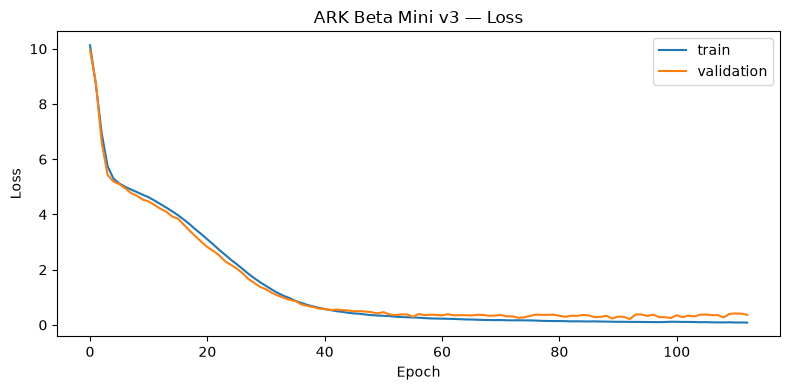

History saved: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\history.json


In [30]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# Restore model, optimizer, epoch, history and cumulative time
restore_training_state(model, optimizer)
last_completed_epoch = start_epoch - 1

target_epoch = last_completed_epoch + EPOCHS_PER_RUN

print(
    f"This session will train {EPOCHS_PER_RUN} additional epoch(s): "
    f"{start_epoch} through {target_epoch}."
)
log_training(
    f"Session target: {EPOCHS_PER_RUN} additional epochs; "
    f"epoch range={start_epoch}-{target_epoch}."
)

for epoch in range(start_epoch, target_epoch + 1):
    start = time.time()

    train_metrics = run_epoch(model, train_loader, optimizer)
    valid_metrics = run_epoch(model, valid_loader)

    epoch_time = time.time() - start
    accumulated_training_time += epoch_time
    last_completed_epoch = epoch

    history["train_loss"].append(train_metrics["loss"])
    history["valid_loss"].append(valid_metrics["loss"])

    valid_loss = valid_metrics["loss"]
    is_best = valid_loss < best_val_loss
    
    if is_best:
        best_val_loss = valid_loss

    log_message = (
        f"Epoch {epoch:02d}/{target_epoch} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"valid loss={valid_loss:.4f} | "
        f"epoch time={epoch_time:.1f}s | "
        f"accumulated training time={accumulated_training_time:.1f}s "
        f"({accumulated_training_time / 60:.2f} min) | "
    )

    print(log_message)
    log_training(log_message)

    if is_best:
        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            model,
            optimizer,
            epoch,
            best_val_loss,
            history
        )

    # Persist history after every epoch
    with open(HISTORY_PATH, "w", encoding="utf-8") as f:
        json.dump(history, f, ensure_ascii=False, indent=2)

final_summary = (
    "\nTraining session finished.\n"
    f"Additional epochs requested this session: {EPOCHS_PER_RUN}\n"
    f"Target cumulative epoch: {target_epoch}\n"
    f"Last completed epoch: {last_completed_epoch}\n"
    f"Accumulated training time: "
    f"{accumulated_training_time:.1f}s "
    f"({accumulated_training_time / 60:.2f} min, "
    f"{accumulated_training_time / 3600:.2f} hours)\n"
    f"Best validation loss: {best_val_loss:.6f}\n"
)

print(final_summary)
log_training(final_summary)
print("Training log saved:", TRAINING_LOG_PATH)

with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["valid_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ARK Beta Mini v3 — Loss")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()

print("History saved:", HISTORY_PATH)

## 🔴 Test

Sample 0: EOS reached=True | generated tokens=23
Saved prediction image: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\prediction_results\fatty_liver_prediction.png
Sample 0: EOS reached=True | generated tokens=19
Saved prediction image: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\prediction_results\tilly_norwood_prediction.png
Sample 0: EOS reached=True | generated tokens=19
Saved prediction image: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\prediction_results\non-alcoholic_fatty_liver_prediction.png
Sample 0: EOS reached=True | generated tokens=27
Saved prediction image: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\prediction_results\iron_man_prediction.png
Sample 0: EOS reached=True | generated tokens=16
Saved prediction image: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-30_11-52-54\prediction_results\lascaux_cave_prediction.png
Sample 0: EOS reached=True | generated tokens=23
Saved p

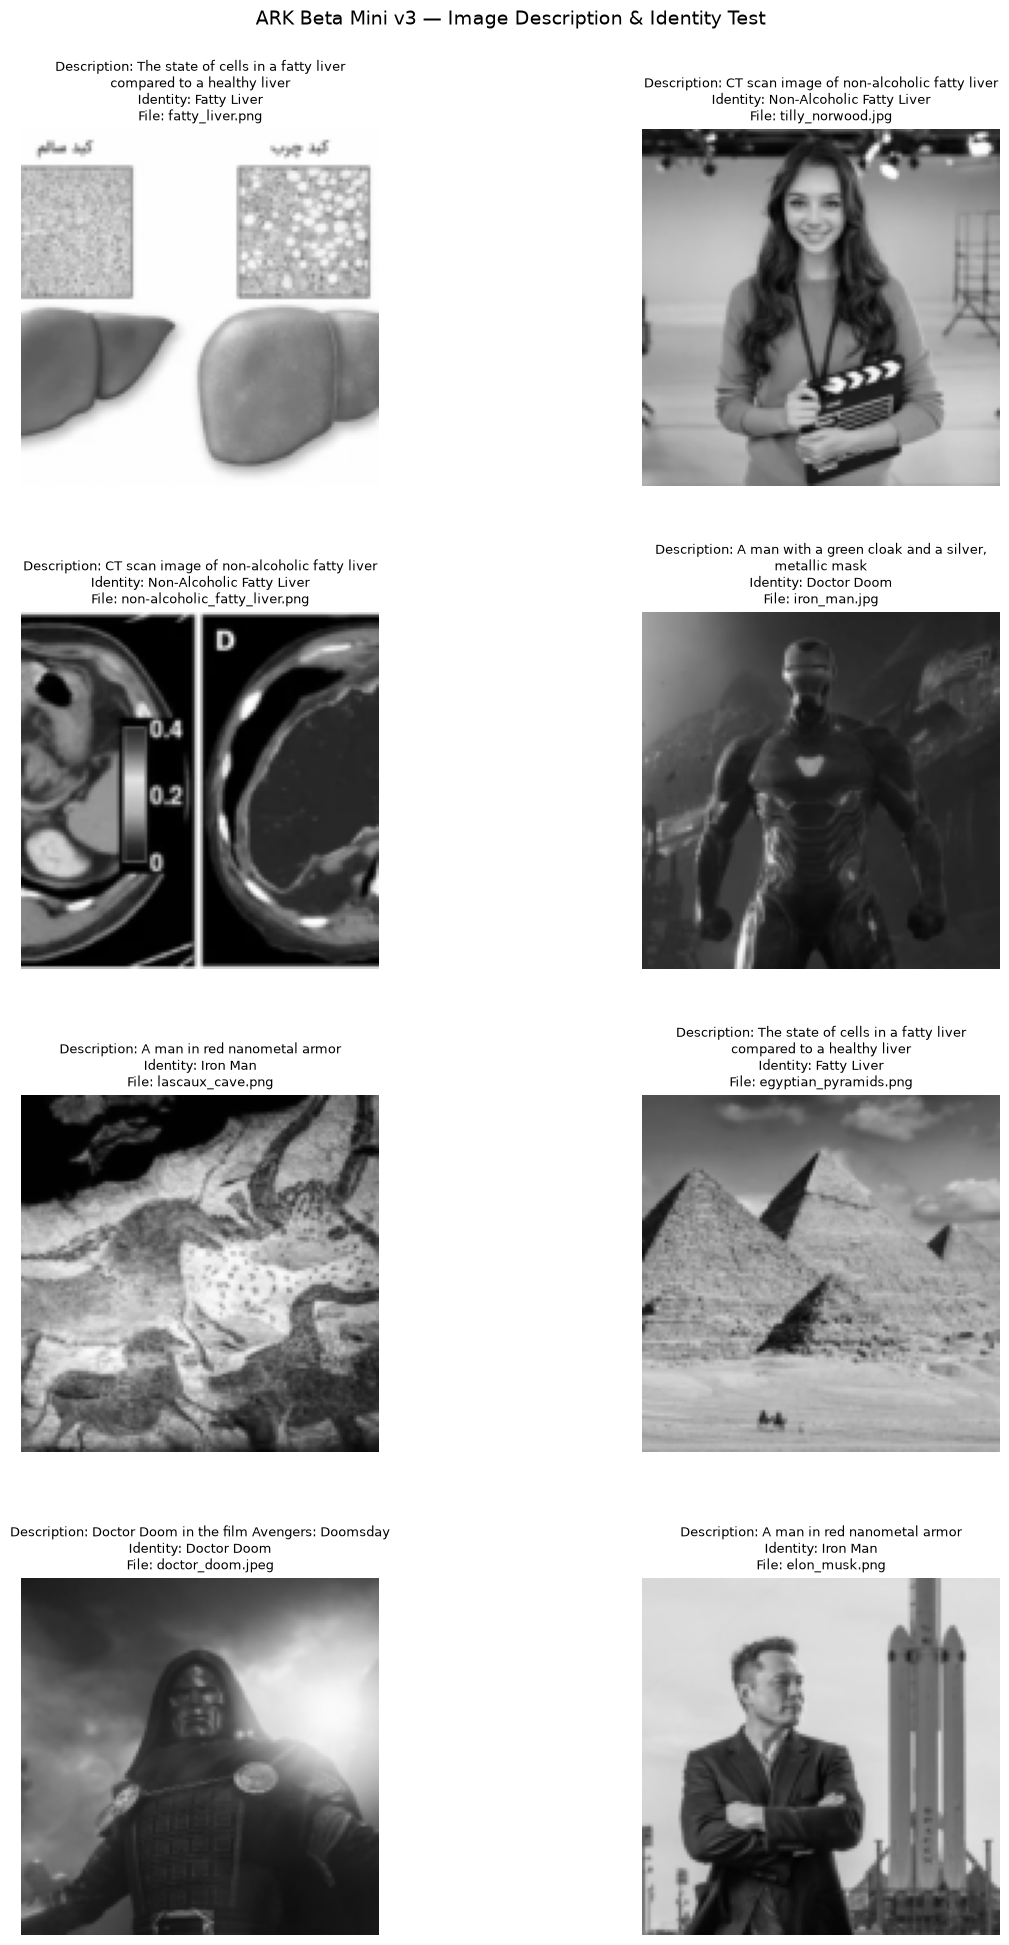

In [31]:
def identify_sample(predicted):
    """
    Extract sample identity from the generated text.

    Expected format:
    Identify | description
    """

    predicted = predicted.strip()

    if "|" not in predicted:
        return {
            "name": None,
            "score": 0.0,
            "description": predicted,
        }

    name, description = predicted.split("|", maxsplit=1)

    name = name.strip()
    description = description.strip()

    if not name:
        name = None

    return {
        "name": name,
        "score": 1.0 if name else 0.0,
        "description": description,
    }

def random_visual_test(
    dataset=test_dataset,
    n_samples=8,
    seed=None,
    request_description=True,
    request_identity=False,
    output_dir=None,
):
    if output_dir is None:
        output_dir = RUN_DIR / "prediction_results"
    
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    if len(dataset) == 0:
        print("Dataset is empty.")
        return

    if not request_description and not request_identity:
        print("Enable at least one request.")
        return

    # Create output directory
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # Randomly select samples
    rng = random.Random(seed)
    indices = rng.sample(
        range(len(dataset)),
        k=min(n_samples, len(dataset)),
    )

    model.eval()

    n_cols = 2
    n_rows = (len(indices) + n_cols - 1) // n_cols

    # Overview figure containing all selected samples
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 5 * n_rows),
        squeeze=False,
    )
    axes = axes.flatten()

    with torch.no_grad():
        for ax, idx in zip(axes, indices):
            (
                image,
                kind,
                class_target,
                seq_target,
                reference,
                path,
            ) = dataset[idx]

            image_batch = image.unsqueeze(0).to(DEVICE)

            # Prepare image for display
            display_image = image.detach().cpu()

            if display_image.shape[0] == 1:
                image_for_plot = np.clip(
                    display_image.squeeze(0).numpy(),
                    0.0,
                    1.0,
                )
                image_cmap = "gray"
            else:
                image_for_plot = np.clip(
                    display_image.permute(1, 2, 0).numpy(),
                    0.0,
                    1.0,
                )
                image_cmap = None

            # Display image in overview
            ax.imshow(
                image_for_plot,
                cmap=image_cmap,
                vmin=0.0 if image_cmap else None,
                vmax=1.0 if image_cmap else None,
            )
            ax.axis("off")

            result_lines = []
            predicted = ""

            if request_description or request_identity:
                # Identity retrieval also needs a generated caption.
                generated_ids = model.generate(
                    image_batch,
                    max_length=MAX_SEQUENCE_LENGTH,
                )[0].cpu().tolist()

                cleaned_ids = []

                for token_id in generated_ids:
                    if token_id == EOS_ID:
                        break

                    if token_id not in (PAD_ID, BOS_ID):
                        cleaned_ids.append(token_id)

                predicted = tokenizer.decode(
                    cleaned_ids,
                    skip_special_tokens=True,
                ).strip()

            
            identity = identify_sample(predicted)
            
            description = identity["description"]
            identity = identity["name"]
            
            # Request 1: Image description
            if request_description:
                result_lines.append(
                    f"Description: "
                    f"{description or 'No description generated'}"
                )
            
            # Request 2: Identity
            if request_identity:
                result_lines.append(
                    f"Identity: {identity or 'Unknown'}"
                )

            result_lines.append(f"File: {Path(path).name}")

            # Update overview
            ax.set_title(
                "\n".join(
                    textwrap.fill(line, width=55)
                    for line in result_lines
                ),
                fontsize=9,
                wrap=True,
            )

            output_path = (
                output_dir
                / f"{Path(path).stem}_prediction.png"
            )

            single_fig, single_ax = plt.subplots(
                figsize=(8, 6),
            )

            single_ax.imshow(
                image_for_plot,
                cmap=image_cmap,
                vmin=0.0 if image_cmap else None,
                vmax=1.0 if image_cmap else None,
            )
            single_ax.axis("off")

            single_ax.set_title(
                "\n".join(
                    textwrap.fill(line, width=55)
                    for line in result_lines
                ),
                fontsize=10,
                wrap=True,
            )

            single_fig.tight_layout()

            single_fig.savefig(
                output_path,
                dpi=150,
                bbox_inches="tight",
            )

            plt.close(single_fig)

            print(f"Saved prediction image: {output_path}")

    # Hide unused overview axes
    for ax in axes[len(indices):]:
        ax.axis("off")

    fig.suptitle(
        "ARK Beta Mini v3 — Image Description & Identity Test",
        fontsize=14,
    )

    plt.tight_layout(
        pad=2.5,
        w_pad=5.0,
        h_pad=4.0,
    )
    plt.show()


random_visual_test(
    dataset=test_dataset,
    n_samples=8,
    seed=None,
    request_description=True,
    request_identity=True,
)

In [32]:
@torch.no_grad()
def inspect_predictions(dataset, n_samples=None):
    model.eval()

    if n_samples is None:
        n_samples = len(dataset)

    for i in range(min(n_samples, len(dataset))):
        image, kind, class_target, seq_target, reference, path = dataset[i]

        image_batch = image.unsqueeze(0).to(DEVICE)

        generated_ids = model.generate(
            image_batch,
            max_length=MAX_SEQUENCE_LENGTH,
        )[0].cpu().tolist()

        cleaned_ids = []

        for token_id in generated_ids:
            if token_id == EOS_ID:
                break
            if token_id not in (PAD_ID, BOS_ID):
                cleaned_ids.append(token_id)

        predicted = tokenizer.decode(
            cleaned_ids,
            skip_special_tokens=True,
        ).strip()

        print(f"File: {Path(path).name}")
        print(f"Reference: {reference}")
        print(f"Prediction: {predicted}")
        print("-" * 60)


print("TRAIN PREDICTIONS")
inspect_predictions(train_dataset)

print("\nTEST PREDICTIONS")
inspect_predictions(test_dataset)

TRAIN PREDICTIONS
Sample 0: EOS reached=True | generated tokens=32
File: asteroid_impact.jpg
Reference: Asteroid Impact | The Chicxulub asteroid impact at the Cretaceous-Paleogene boundary
Prediction: Asteroid Impact | The Chicxulub asteroid impact at the Cretaceous-Paleogene boundary
------------------------------------------------------------
Sample 0: EOS reached=True | generated tokens=23
File: cheyava_falls.jpg
Reference: Cheyava Falls | An image of Cheyava Falls, where the white markings might be traces of ancient microbial activity
Prediction: Fatty Liver | The state of cells in a fatty liver compared to a healthy liver
------------------------------------------------------------
Sample 0: EOS reached=True | generated tokens=25
File: cretaceous.jpg
Reference: Cretaceous Period | Dinosaurs roaming a prehistoric landscape
Prediction: Iron Man | A man in red nano-metal armor and a golden mask
------------------------------------------------------------
Sample 0: EOS reached=True | 